# Thailand's hidden hub dependency: which foreign transit hubs can Thailand not afford to lose?
**MADT 7202 · Mid-term applied case · notebook (evidence for the one-page report)**

**Decision:** the product manager of a Thai tour operator selling Latin America and Caribbean trips decides which transit hubs need a backup route.

**Why a network:** a table ranks hubs by size. It cannot say which markets Thailand loses when one hub is removed, because that depends on whether *another* hub also reaches that market: a property of paths, not of rows.

**How to use:** Runtime → Run all. Numbers for the report are printed in the **REPORT NUMBERS** cell; the figure is saved as `fig_hub_dependency.png`.

## 1 · Data
- **Source:** OpenFlights routes + airports (open dataset, official GitHub repository). **Licence:** ODbL, attribution required.
- **Period:** snapshot June 2014 (limitation; corrected by a hand check in section 6).
- **Scope:** the whole world, because Thailand's onward connections go everywhere.

In [1]:
import pandas as pd, numpy as np, networkx as nx, matplotlib.pyplot as plt, json, urllib.request
BASE = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/"
ap = pd.read_csv(BASE + "airports.dat", header=None,
    names=["id","name","city","country","iata","icao","lat","lon","alt","tz","dst","tzdb","type","source"])
ap = ap[ap.iata.str.fullmatch(r"[A-Z]{3}", na=False)].set_index("iata")
C = ap.country.to_dict()
ROUTES = pd.read_csv(BASE + "routes.dat", header=None,
    names=["airline","airline_id","src","src_id","dst","dst_id","codeshare","stops","equipment"])
print("Airports:", len(ap), "| route records:", len(ROUTES))

Airports: 6071 | route records: 67663


## 2 · Graph construction
- **Node:** an airport. **Edge (directed):** at least one airline flies A → B nonstop. Codeshares excluded (they double count).
- **Thailand** is treated as one origin: any Thai airport counts (identity choice).
- **Reached directly:** a country with a nonstop flight from Thailand.
- **Reached with one stop:** Thailand → foreign hub → country, for countries with no nonstop.
- **Pruning:** destination countries with fewer than `MIN_ROUTES` departing routes are dropped (tiny territories behave like generic words: they attach to one colonial-era hub and mean little as markets).

In [2]:
def build(codeshare=False):
    r = ROUTES[(ROUTES.stops == 0) & ROUTES.src.isin(ap.index) & ROUTES.dst.isin(ap.index) & (ROUTES.src != ROUTES.dst)]
    if not codeshare: r = r[r.codeshare != "Y"]
    G = nx.DiGraph(); G.add_edges_from(zip(r.src, r.dst)); return G

def analyse(G, min_routes=10, drop_hubs=(), level="country"):
    """Return (hub table, via) where via[destination] = set of hubs that connect Thailand to it with one stop."""
    thai = [n for n in G if C[n] == "Thailand"]
    hubs = {d for t in thai for d in G[t] if C[d] != "Thailand" and d not in drop_hubs}
    direct_countries = {C[h] for h in hubs}
    size = pd.Series({n: G.out_degree(n) for n in G}).groupby(pd.Series(C)).sum()
    via = {}
    for h in hubs:
        for d in G[h]:
            c = C[d]
            if c == "Thailand": continue
            if level == "country":
                if c in direct_countries or size.get(c, 0) < min_routes: continue
                via.setdefault(c, set()).add(h)
            else:                                   # airport level (the naive alternative)
                if d in hubs: continue
                via.setdefault(d, set()).add(h)
    rows = []
    for h in hubs:
        served = [x for x, hs in via.items() if h in hs]
        sole = sorted(x for x in served if len(via[x]) == 1)
        two = sorted(x for x in served if len(via[x]) == 2)
        rows.append({"hub": h, "city": ap.loc[h, "city"], "country": C[h], "routes": G.out_degree(h),
                     "reached_via_hub": len(served), "only_via_this_hub": len(sole), "only_two_hubs": len(two),
                     "list_only_via": ", ".join(sole)})
    return pd.DataFrame(rows).set_index("hub"), via, hubs, direct_countries

MIN_ROUTES = 10
G = build()
T, via, hubs, direct_c = analyse(G, MIN_ROUTES)
print(f"World graph: {G.number_of_nodes()} airports, {G.number_of_edges()} directed routes")
print(f"Thailand flies nonstop to {len(hubs)} foreign airports in {len(direct_c)} countries")
print(f"Countries reachable only with one stop: {len(via)}")
B = nx.Graph(); B.add_edges_from((h, c) for c, hs in via.items() for h in hs)
print(f"Report graph (hub - country, bipartite): {B.number_of_nodes()} nodes, {B.number_of_edges()} edges")
fragile = {c: hs for c, hs in via.items() if len(hs) == 1}
print(f"After pruning to countries with exactly one hub: {len(set(h for hs in fragile.values() for h in hs))} hubs + {len(fragile)} countries = {len(fragile)} edges")

World graph: 3030 airports, 33987 directed routes
Thailand flies nonstop to 116 foreign airports in 55 countries
Countries reachable only with one stop: 106
Report graph (hub - country, bipartite): 184 nodes, 954 edges
After pruning to countries with exactly one hub: 8 hubs + 15 countries = 15 edges


## 3 · Big hub vs hub Thailand depends on
`routes` is what a table shows. `only_via_this_hub` is what the graph shows: countries Thailand loses one-stop access to if this hub closes.

In [3]:
cols = ["city", "routes", "reached_via_hub", "only_via_this_hub", "only_two_hubs", "list_only_via"]
print("=== Ten biggest hubs Thailand flies to ==="); display(T.sort_values("routes", ascending=False).head(10)[cols])
print("=== Hubs Thailand depends on ==="); display(T[T.only_via_this_hub > 0].sort_values(["only_via_this_hub", "routes"], ascending=False)[cols])
rho = T[T.reached_via_hub > 0][["routes", "only_via_this_hub"]].corr(method="spearman").iloc[0, 1]
print(f"Rank correlation between hub size and dependency: {rho:.2f}")
REGION = {"Bolivia":"Latin America / Caribbean","Costa Rica":"Latin America / Caribbean","Guatemala":"Latin America / Caribbean","Uruguay":"Latin America / Caribbean",
          "Jamaica":"Latin America / Caribbean","Puerto Rico":"Latin America / Caribbean","Trinidad and Tobago":"Latin America / Caribbean","Guadeloupe":"Latin America / Caribbean",
          "Martinique":"Latin America / Caribbean","Aruba":"Latin America / Caribbean","Bahamas":"Latin America / Caribbean","Ecuador":"Latin America / Caribbean"}
reg = pd.Series({c: REGION.get(c, "other") for c in fragile}).value_counts()
print("\nSingle-hub countries by region:"); print(reg.to_string())

=== Ten biggest hubs Thailand flies to ===


,city,routes,reached_via_hub,only_via_this_hub,only_two_hubs,list_only_via
hub,,,,,,
CDG,Paris,237,59,3,1,"Guadeloupe, Martinique, Mauritania"
IST,Istanbul,226,48,0,0,
FRA,Frankfurt,225,49,3,2,"Jamaica, Puerto Rico, Trinidad and Tobago"
AMS,Amsterdam,213,43,1,3,Aruba
PEK,Beijing,204,7,0,0,
DXB,Dubai,187,40,0,0,
DME,Moscow,186,21,0,0,
LHR,London,171,34,1,1,Bahamas
MUC,Munich,162,29,0,0,


=== Hubs Thailand depends on ===


,city,routes,reached_via_hub,only_via_this_hub,only_two_hubs,list_only_via
hub,,,,,,
MAD,Madrid,138,36,4,2,"Bolivia, Costa Rica, Guatemala, Uruguay"
CDG,Paris,237,59,3,1,"Guadeloupe, Martinique, Mauritania"
FRA,Frankfurt,225,49,3,2,"Jamaica, Puerto Rico, Trinidad and Tobago"
AMS,Amsterdam,213,43,1,3,Aruba
LHR,London,171,34,1,1,Bahamas
CPH,Copenhagen,116,22,1,0,Greenland
OSL,Oslo,100,18,1,0,Slovakia
BNE,Brisbane,49,6,1,0,Solomon Islands


Rank correlation between hub size and dependency: 0.35

Single-hub countries by region:
Latin America / Caribbean    11
other                         4


## 4 · Construction choice against a named alternative: country level vs airport level
Counting single-hub **airports** instead of **countries** looks more detailed but measures the hub's own domestic network.

In [4]:
TA, viaA, _, _ = analyse(G, level="airport")
a = TA.sort_values("only_via_this_hub", ascending=False).head(6)[["city", "routes", "only_via_this_hub"]]
a["of_which_in_hub's_own_country"] = [sum(1 for x, hs in viaA.items() if hs == {h} and C[x] == C[h]) for h in a.index]
a["same_hub_at_country_level"] = [T.loc[h, "only_via_this_hub"] for h in a.index]
print("=== Airport-level ranking (the alternative) ==="); display(a)

=== Airport-level ranking (the alternative) ===


,city,routes,only_via_this_hub,of_which_in_hub's_own_country,same_hub_at_country_level
hub,,,,,
IST,Istanbul,226,34,28,0
MNL,Manila,76,28,28,0
ARN,Stockholm,112,21,19,0
OSL,Oslo,100,20,17,1
CDG,Paris,237,19,4,3
HND,Tokyo,72,18,18,0


## 5 · Robustness
Does the top of the ranking survive the pruning cutoff and the codeshare choice?

In [5]:
def top(df, k=3): 
    d = df.sort_values(["only_via_this_hub", "routes"], ascending=False).head(k)
    return ", ".join(f"{h} ({n})" for h, n in zip(d.index, d.only_via_this_hub))
rob = pd.DataFrame({
    "Cutoff 5 routes":  {"top-3 (countries only via hub)": top(analyse(G, 5)[0])},
    "Cutoff 10 routes (base)": {"top-3 (countries only via hub)": top(T)},
    "Cutoff 20 routes": {"top-3 (countries only via hub)": top(analyse(G, 20)[0])},
    "Codeshares included": {"top-3 (countries only via hub)": top(analyse(build(True), MIN_ROUTES)[0])},
}).T
display(rob)

,top-3 (countries only via hub)
Cutoff 5 routes,"CDG (5), MAD (4), FRA (3)"
Cutoff 10 routes (base),"MAD (4), CDG (3), FRA (3)"
Cutoff 20 routes,"FRA (3), MAD (3), AMS (1)"
Codeshares included,"MAD (4), FRA (3), CDG (3)"


## 6 · 2026 correction (second source, by hand)
The 2014 snapshot may list nonstop routes from Thailand that no longer exist. Check each gateway hub below on Google Flights (nonstop filter) and put the ones **no longer served nonstop from Thailand** in `DROPPED_2026`. The cell then recomputes what Thailand loses.

In [6]:
gate = T[T.only_via_this_hub > 0].sort_values("only_via_this_hub", ascending=False)
check = gate[["city", "country", "list_only_via"]].copy(); check["nonstop_from_Thailand_in_2026 (Y/N)"] = ""
check.to_csv("verify_gateway_hubs_2026.csv"); display(check)

DROPPED_2026 = []        # e.g. ["MAD"] after your check
T26, via26, _, _ = analyse(G, MIN_ROUTES, drop_hubs=tuple(DROPPED_2026))
lost = sorted(set(via) - set(via26))
print("Dropped hubs:", DROPPED_2026 or "none yet")
print("Countries with NO one-stop access left:", lost or "none")
print("New single-hub ranking:", top(T26, 5))

,city,country,list_only_via,nonstop_from_Thailand_in_2026 (Y/N)
hub,,,,
MAD,Madrid,Spain,"Bolivia, Costa Rica, Guatemala, Uruguay",
FRA,Frankfurt,Germany,"Jamaica, Puerto Rico, Trinidad and Tobago",
CDG,Paris,France,"Guadeloupe, Martinique, Mauritania",
AMS,Amsterdam,Netherlands,Aruba,
OSL,Oslo,Norway,Slovakia,
LHR,London,United Kingdom,Bahamas,
BNE,Brisbane,Australia,Solomon Islands,
CPH,Copenhagen,Denmark,Greenland,


Dropped hubs: none yet
Countries with NO one-stop access left: none
New single-hub ranking: MAD (4), CDG (3), FRA (3), AMS (1), LHR (1)


## 7 · The picture

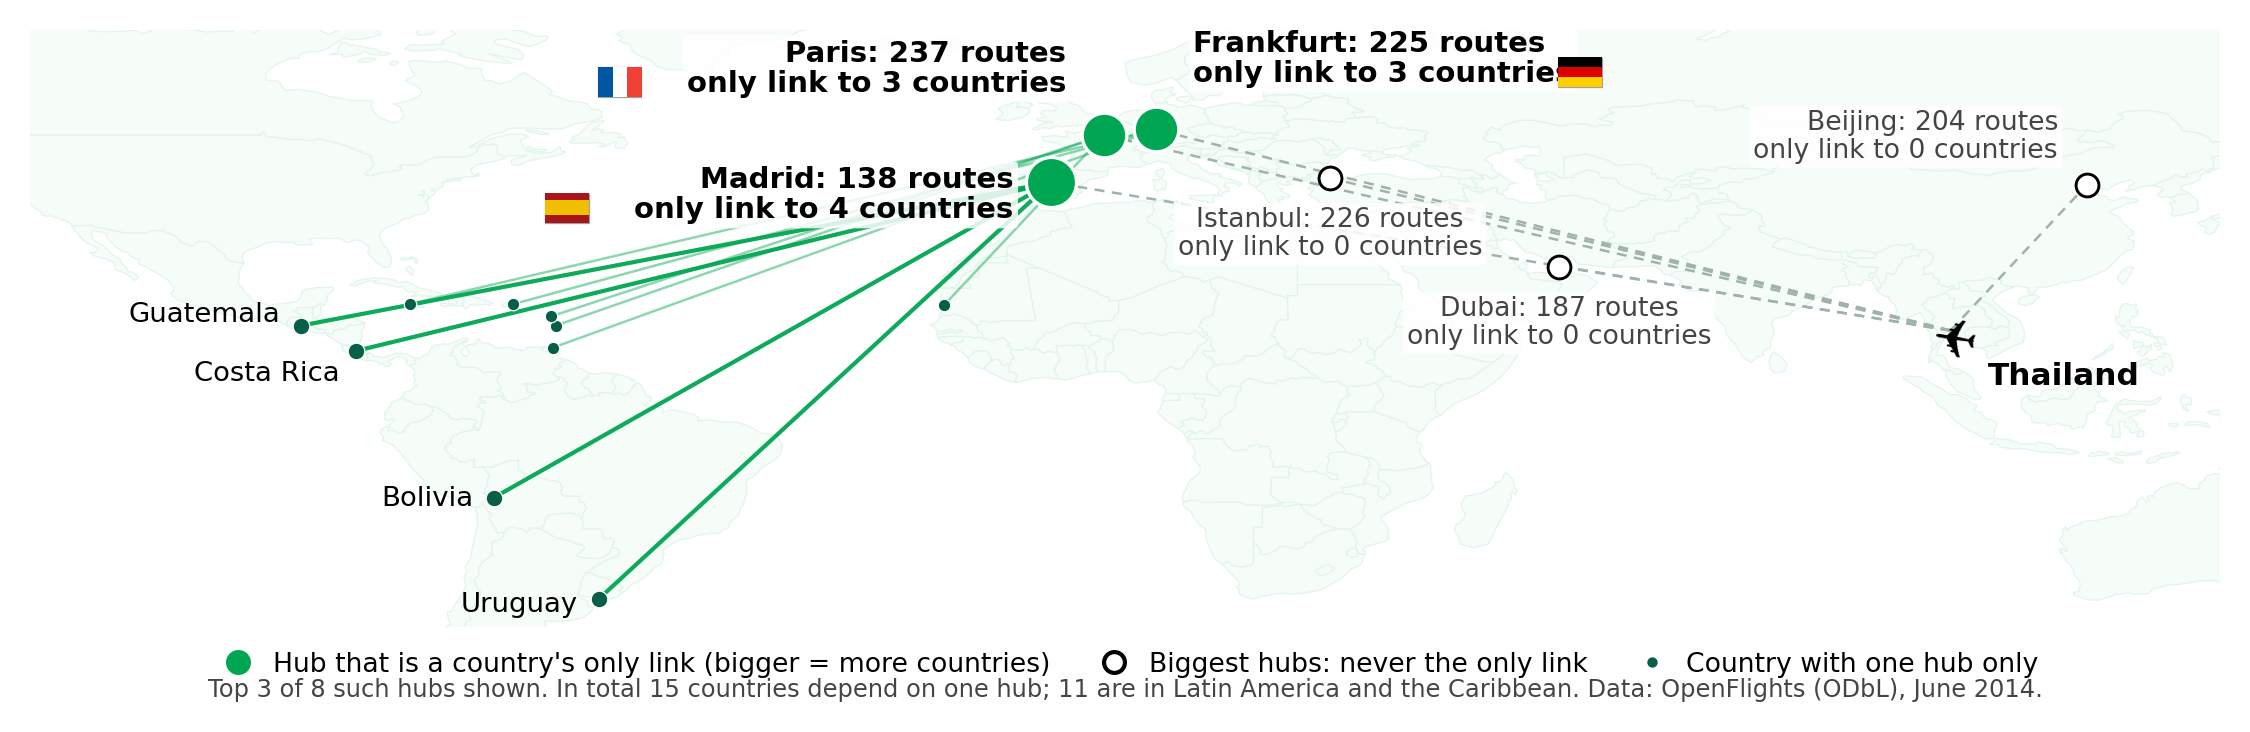

In [7]:
from matplotlib.collections import PolyCollection
world = json.load(urllib.request.urlopen("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"))
def polys(g):
    r = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]; return [x[0] for x in r]
land = [p for f in world["features"] for p in polys(f["geometry"])]
RED, INK, GREY, ORANGE = "#065f46", "#0b1f17", "#7c8a84", "#00a651"
P = lambda n: (ap.loc[n, "lon"], ap.loc[n, "lat"])
out = pd.Series({n: G.out_degree(n) for n in G})
main_airport = lambda c: out[[n for n in G if C[n] == c]].idxmax()
TH = "BKK"
dep = T[T.only_via_this_hub > 0].sort_values(["only_via_this_hub", "routes"], ascending=False)
top3 = dep.head(3)      # the three hubs Thailand depends on most
big0 = T[(T.only_via_this_hub == 0)].sort_values("routes", ascending=False).head(3)
NL = chr(10)
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(7.3, 2.25), dpi=300)
ax.set_facecolor("#ffffff")
ax.add_collection(PolyCollection(land, facecolors="#f6fdf8", edgecolors="#e2f5ea", linewidths=0.3, zorder=0))
# step 1: Thailand flies nonstop to the hub (dashed grey)
for h in list(top3.index) + list(big0.index):
    ax.plot([P(TH)[0], P(h)[0]], [P(TH)[1], P(h)[1]], color="#9fb3aa", lw=0.6, ls=(0, (4, 3)), zorder=1)
# step 2: the hub is the ONLY one-stop link to these countries (solid purple)
first = top3.index[0]
C_OFF = {"Bolivia": (-5, -2, "right"), "Uruguay": (-5, -3, "right"), "Costa Rica": (-4, -7, "right"), "Guatemala": (-5, 1, "right")}
for h in top3.index[::-1]:
    strong = h == first
    for c in [x for x, hs in via.items() if hs == {h}]:
        m = main_airport(c)
        ax.plot([P(h)[0], P(m)[0]], [P(h)[1], P(m)[1]], color=ORANGE, lw=1.0 if strong else 0.6, alpha=0.95 if strong else 0.45, zorder=2)
        ax.scatter(*P(m), s=16 if strong else 9, color=RED, zorder=3, edgecolors="white", linewidths=0.3)
        if strong:
            dx, dy, ha = C_OFF.get(c, (-5, -2, "right"))
            ax.annotate(c, P(m), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=6.6, color="black", zorder=6)
for h in top3.index:
    ax.scatter(*P(h), s=25 + 30 * top3.loc[h, "only_via_this_hub"], color=ORANGE, edgecolors="white", linewidths=0.8, zorder=4)
for h in big0.index:
    ax.scatter(*P(h), s=30, color="white", edgecolors="black", linewidths=0.7, zorder=4)
ax.annotate("Thailand", P(TH), xytext=(9, -13), textcoords="offset points", fontsize=7.5, fontweight="bold", color="black")
OFF = {"MAD": (-9, -3, "right", "center"), "FRA": (9, 10, "left", "bottom"), "CDG": (-9, 9, "right", "bottom"),
       "IST": (0, -7, "center", "top"), "DXB": (0, -7, "center", "top"), "PEK": (-7, 5, "right", "bottom")}
box = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85)
lab = {}
for h in top3.index:
    dx, dy, ha, va = OFF.get(h, (6, 6, "left", "bottom"))
    lab[h] = ax.annotate(f"{top3.loc[h,'city']}: {top3.loc[h,'routes']} routes" + NL + f"only link to {top3.loc[h,'only_via_this_hub']} countries", P(h), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va=va, fontsize=7, fontweight="bold", color="black", linespacing=1.1, bbox=box, zorder=7)
for h in big0.index:
    dx, dy, ha, va = OFF.get(h, (6, 6, "left", "bottom"))
    ax.annotate(f"{big0.loc[h,'city']}: {big0.loc[h,'routes']} routes" + NL + "only link to 0 countries", P(h), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va=va, fontsize=6.4, color="#444444", linespacing=1.1, bbox=box, zorder=7)
ax.set_xlim(-122, 132); ax.set_ylim(-40, 68); ax.set_xticks([]); ax.set_yticks([])
for s_ in ax.spines.values(): s_.set_visible(False)
# small plane at Thailand, nose pointing at the Europe hubs
fig.subplots_adjust(left=0, right=1, top=1, bottom=0.115)
p0, p1 = ax.transData.transform([P(TH), P(top3.index[0])])
ang = np.degrees(np.arctan2(p1[1] - p0[1], p1[0] - p0[0]))
ax.text(*P(TH), chr(0x2708), fontsize=13, rotation=ang, rotation_mode="anchor", ha="center", va="center", color="black", zorder=5)
handles = [Line2D([], [], marker="o", ls="", ms=7, mfc=ORANGE, mec="white", label="Hub that is a country's only link (bigger = more countries)"),
           Line2D([], [], marker="o", ls="", ms=5, mfc="white", mec="black", label="Biggest hubs: never the only link"),
           Line2D([], [], marker="o", ls="", ms=3.5, mfc=RED, mec="white", label="Country with one hub only")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False, fontsize=6.4, handletextpad=0.3, columnspacing=1.4)
n_latam = int(reg.get("Latin America / Caribbean", 0))
fig.text(0.5, 0.012, f"Top 3 of {len(dep)} such hubs shown. In total {int(dep.only_via_this_hub.sum())} countries depend on one hub; {n_latam} are in Latin America and the Caribbean. Data: OpenFlights (ODbL), June 2014.",
         ha="center", fontsize=5.8, color="#444444")
# small flags next to the three hub labels (drawn as plain colour bands)
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.colors import to_rgb
def bands(colors, weights, vertical=False, h=28, w=42):
    n = w if vertical else h
    edges = np.cumsum([0] + list(weights)) / sum(weights) * n
    line = np.zeros((n, 3))
    for c, a, b in zip(colors, edges[:-1], edges[1:]): line[int(round(a)):int(round(b))] = to_rgb(c)
    return np.repeat(line[None, :, :], h, axis=0) if vertical else np.repeat(line[:, None, :], w, axis=1)
FLAGS = {"Spain": bands(["#AA151B", "#F1BF00", "#AA151B"], [1, 2, 1]),
         "France": bands(["#0055A4", "#FFFFFF", "#EF4135"], [1, 1, 1], vertical=True),
         "Germany": bands(["#000000", "#DD0000", "#FFCE00"], [1, 1, 1])}
fig.subplots_adjust(left=0, right=1, top=1, bottom=0.115); fig.canvas.draw()
px = fig.dpi / 72
for h, a in lab.items():
    if C[h] not in FLAGS: continue
    bb = a.get_window_extent()
    right_side = a.get_ha() == "left"
    x = bb.x1 + 9 * px if right_side else bb.x0 - 9 * px
    y = bb.y1 - bb.height * 0.27
    ax.add_artist(AnnotationBbox(OffsetImage(FLAGS[C[h]], zoom=0.25, interpolation="nearest"), (x, y), xycoords="figure pixels",
                                 frameon=True, pad=0, bboxprops=dict(edgecolor="#9aa3a0", linewidth=0.3), zorder=8))
plt.savefig("fig_hub_dependency.png", dpi=300); plt.show()

## 8 · REPORT NUMBERS

In [8]:
print("DATA:", len(ROUTES), "route records; June 2014; OpenFlights (ODbL)")
print("GRAPH:", G.number_of_nodes(), "airports,", G.number_of_edges(), "directed routes; report graph", B.number_of_nodes(), "nodes,", B.number_of_edges(), "edges; pruned to", len(fragile), "single-hub countries")
print("THAILAND: nonstop to", len(hubs), "foreign airports in", len(direct_c), "countries;", len(via), "more countries need one stop")
print("BIGGEST HUBS:"); print(T.sort_values("routes", ascending=False).head(6)[["city", "routes", "only_via_this_hub"]].to_string())
print("DEPENDED-ON HUBS:"); print(gate[["city", "routes", "only_via_this_hub", "list_only_via"]].to_string())
print("SINGLE-HUB COUNTRIES:", len(fragile), "| by region:", reg.to_dict())
print("RANK CORRELATION size vs dependency:", round(rho, 2))
print("ROBUSTNESS:"); print(rob.to_string())

DATA: 67663 route records; June 2014; OpenFlights (ODbL)
GRAPH: 3030 airports, 33987 directed routes; report graph 184 nodes, 954 edges; pruned to 15 single-hub countries
THAILAND: nonstop to 116 foreign airports in 55 countries; 106 more countries need one stop
BIGGEST HUBS:
          city  routes  only_via_this_hub
hub                                      
CDG      Paris     237                  3
IST   Istanbul     226                  0
FRA  Frankfurt     225                  3
AMS  Amsterdam     213                  1
PEK    Beijing     204                  0
DXB      Dubai     187                  0
DEPENDED-ON HUBS:
           city  routes  only_via_this_hub                              list_only_via
hub                                                                                  
MAD      Madrid     138                  4    Bolivia, Costa Rica, Guatemala, Uruguay
FRA   Frankfurt     225                  3  Jamaica, Puerto Rico, Trinidad and Tobago
CDG       Paris     237  